In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully")

All libraries imported successfully


In [75]:
import pandas as pd
df = pd.read_csv('/content/Sample - Superstore.csv' , encoding='latin1')
print("Dataset loaded successfully")

Dataset loaded successfully


In [76]:
df.head()
df.tail()
df.shape
df.columns
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [77]:
print("Total Rows:",df.shape[0])
print("Total Coloums:",df.shape[1])
df.columns.tolist()

Total Rows: 9994
Total Coloums: 21


['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [78]:
df.isnull().sum()
df.duplicated().sum()
df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [79]:
df.dtypes.value_counts()

,count
object,15
int64,3
float64,3


In [80]:
df.select_dtypes(include='object').columns
df.select_dtypes(include=['int64', 'float64']).columns
df.isnull().sum()
df.duplicated().sum()

np.int64(0)

In [81]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df[['Order Date', 'Ship Date']].dtypes

,0
Order Date,datetime64[ns]
Ship Date,datetime64[ns]


In [82]:
total_sales = df['Sales'].sum()

print("Total Sales:", total_sales)

Total Sales: 2297200.8603


In [83]:
total_profit = df['Profit'].sum()

print("Total Profit:", total_profit)

Total Profit: 286397.0217


In [84]:
total_orders = df['Order ID'].nunique()

print("Total Orders:", total_orders)

Total Orders: 5009


In [85]:
total_customers = df['Customer ID'].nunique()

print("Total Customers:", total_customers)

Total Customers: 793


In [86]:
average_sales = df['Sales'].mean()

print("Average Sales:", average_sales)

Average Sales: 229.85800083049827


In [87]:
average_profit = df['Profit'].mean()

print("Average Profit:", average_profit)

Average Profit: 28.65689630778467


In [88]:
print("========== SALES SUMMARY ==========")

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Sales:", round(average_sales, 2))
print("Average Profit:", round(average_profit, 2))


========== SALES SUMMARY ==========
Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Average Sales: 229.86
Average Profit: 28.66


In [89]:
df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Month_Name'] = df['Order Date'].dt.month_name()

In [90]:
monthly_sales = df.groupby(
    ['Year', 'Month', 'Month_Name']
)['Sales'].sum().reset_index()

monthly_sales.head()

,Year,Month,Month_Name,Sales
0,2014,1,January,14236.895
1,2014,2,February,4519.892
2,2014,3,March,55691.009
3,2014,4,April,28295.345
4,2014,5,May,23648.287


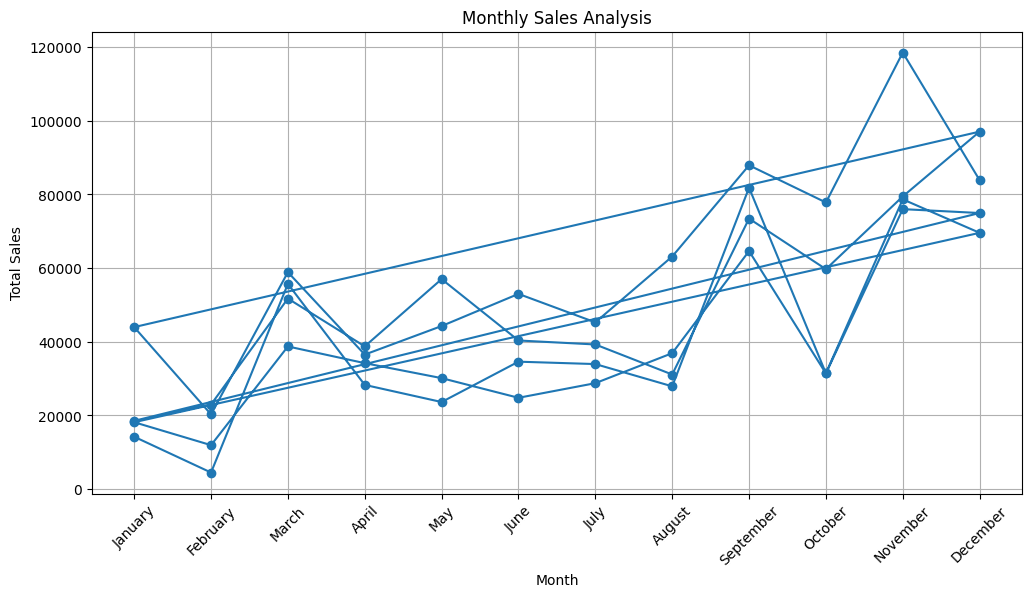

In [91]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales['Month_Name'],
    monthly_sales['Sales'],
    marker='o'
)

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.grid()
plt.show()

In [92]:
highest_month = monthly_sales.loc[
    monthly_sales['Sales'].idxmax()
]

print("Highest Sales Month:")
print(highest_month)

Highest Sales Month:
Year                2017
Month                 11
Month_Name      November
Sales         118447.825
Name: 46, dtype: object


In [93]:
lowest_month = monthly_sales.loc[
    monthly_sales['Sales'].idxmin()
]

print("Lowest Sales Month:")
print(lowest_month)

Lowest Sales Month:
Year              2014
Month                2
Month_Name    February
Sales         4519.892
Name: 1, dtype: object


In [94]:
product_sales = df.groupby('Product Name')['Sales'].sum()

top_10_products = product_sales.sort_values(
    ascending=False
).head(10)

print(top_10_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


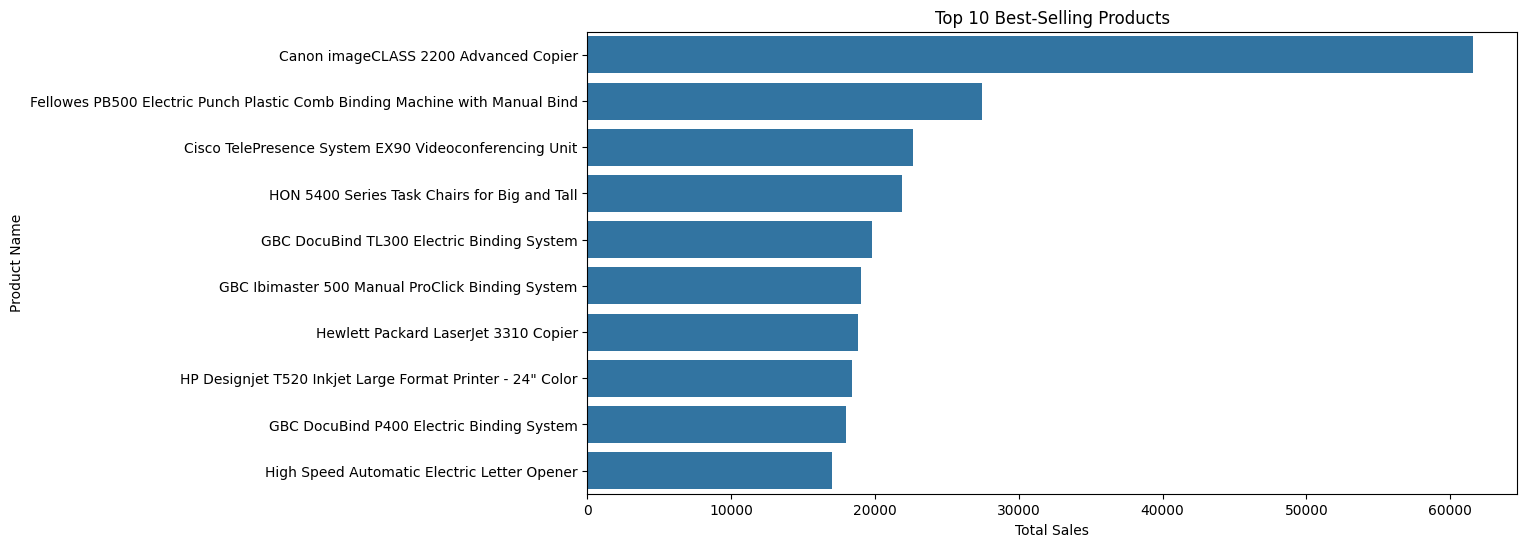

In [95]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_products.values,
    y=top_10_products.index
)

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')

plt.show()

In [96]:
category_sales = df.groupby('Category')['Sales'].sum()

print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


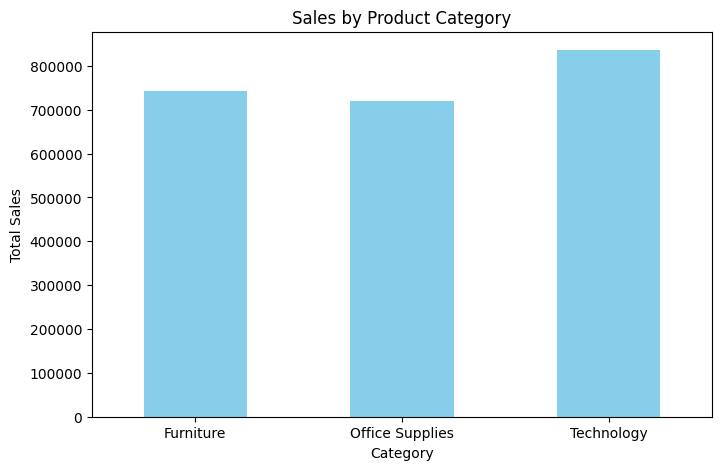

In [97]:
plt.figure(figsize=(8, 5))

category_sales.plot(
    kind='bar',
    color='skyblue'
)

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

In [98]:
subcategory_sales = df.groupby(
    'Sub-Category'
)['Sales'].sum().sort_values(ascending=False)

print(subcategory_sales)

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


In [99]:
print("Highest Selling Category:")
print(category_sales.idxmax())

print("Highest Selling Sub-Category:")
print(subcategory_sales.idxmax())

Highest Selling Category:
Technology
Highest Selling Sub-Category:
Phones


In [100]:
customer_sales = (
    df.groupby('Customer Name')['Sales']
    .sum()
    .sort_values(ascending=False)
)

top_10_customers = customer_sales.head(10)

print(top_10_customers)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


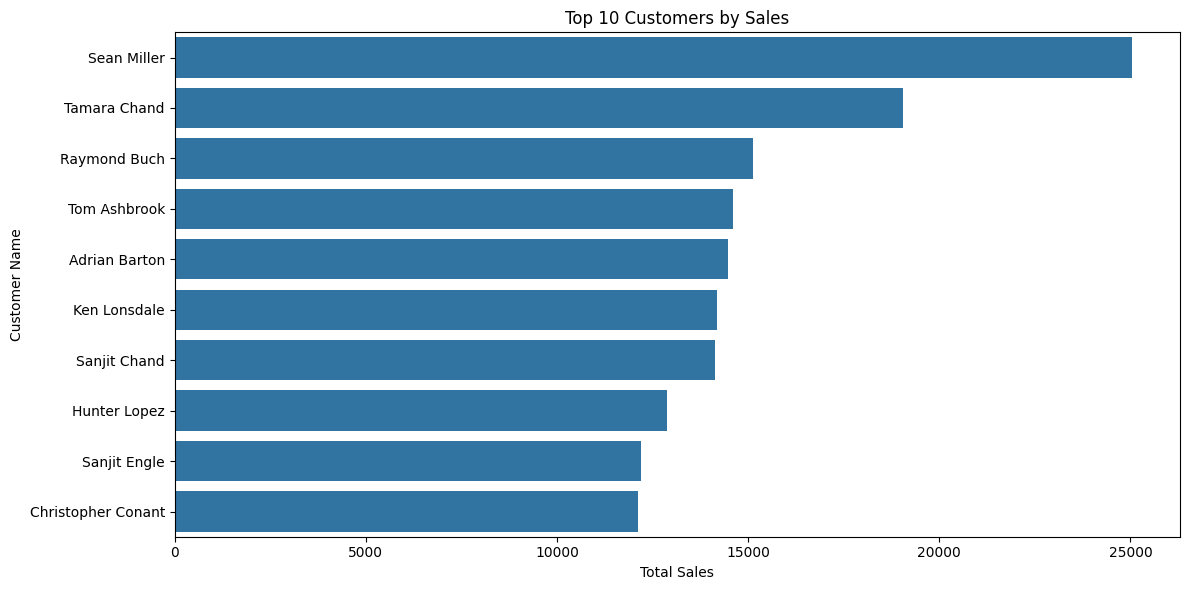

In [101]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_customers.values,
    y=top_10_customers.index
)

plt.title('Top 10 Customers by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Customer Name')

plt.tight_layout()
plt.show()

In [102]:
segment_sales = (
    df.groupby('Segment')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(segment_sales)

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


In [103]:
order_sales = df.groupby('Order ID')['Sales'].sum()

average_order_value = order_sales.mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 458.61


In [104]:
region_sales = (
    df.groupby('Region')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Region:")
print(region_sales)

Sales by Region:
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


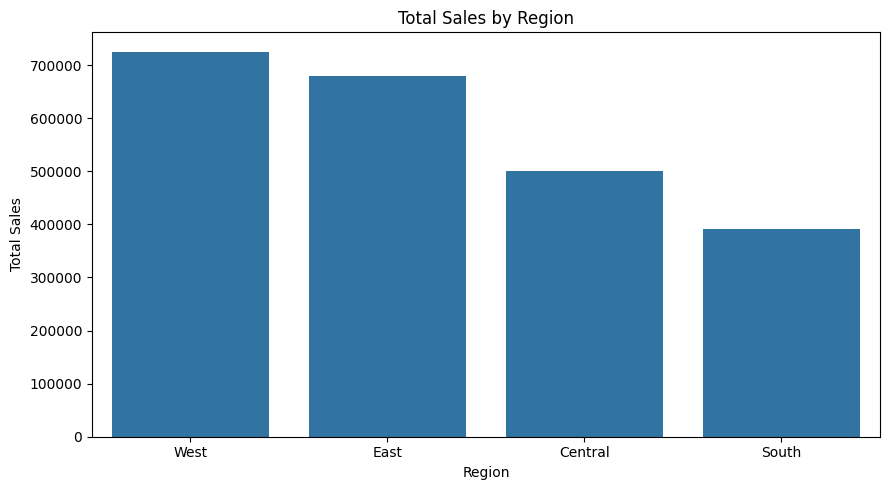

In [105]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [106]:
state_sales = (
    df.groupby('State')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 States by Sales:")
print(state_sales.head(10))

Top 10 States by Sales:
State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64


In [107]:
city_sales = (
    df.groupby('City')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Cities by Sales:")
print(city_sales.head(10))

Top 10 Cities by Sales:
City
New York City    256368.1610
Los Angeles      175851.3410
Seattle          119540.7420
San Francisco    112669.0920
Philadelphia     109077.0130
Houston           64504.7604
Chicago           48539.5410
San Diego         47521.0290
Jacksonville      44713.1830
Springfield       43054.3420
Name: Sales, dtype: float64


In [108]:
region_profit = (
    df.groupby('Region')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Region:")
print(region_profit)

Profit by Region:
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


In [109]:
regional_summary = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).sort_values(
    by='Total_Sales',
    ascending=False
)

display(regional_summary)

,Total_Sales,Total_Profit,Total_Orders
Region,,,
West,725457.8245,108418.4489,1611
East,678781.2400,91522.7800,1401
Central,501239.8908,39706.3625,1175
South,391721.9050,46749.4303,822


In [110]:
category_profit = (
    df.groupby('Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Category:")
print(category_profit)

Profit by Category:
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


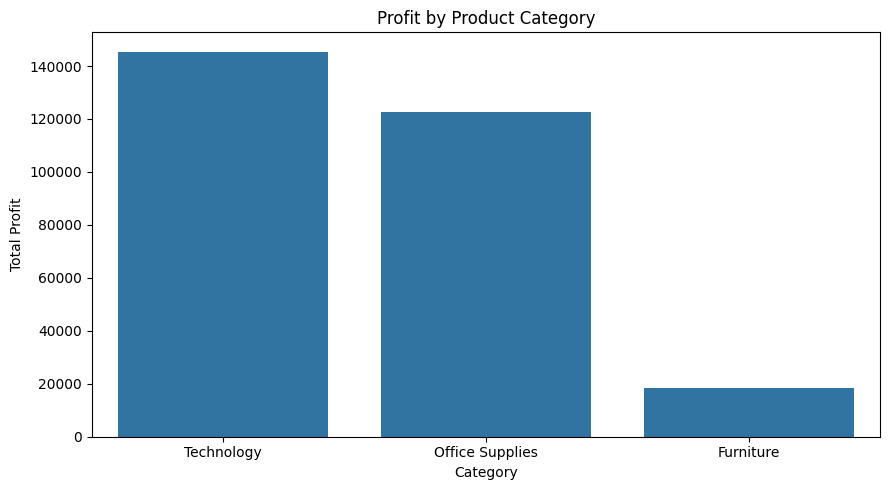

In [111]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title('Profit by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.show()

In [112]:
subcategory_profit = (
    df.groupby('Sub-Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Sub-Category:")
print(subcategory_profit)

Profit by Sub-Category:
Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


In [113]:
subcategory_profit = (
    df.groupby('Sub-Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Sub-Category:")
print(subcategory_profit)

Profit by Sub-Category:
Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


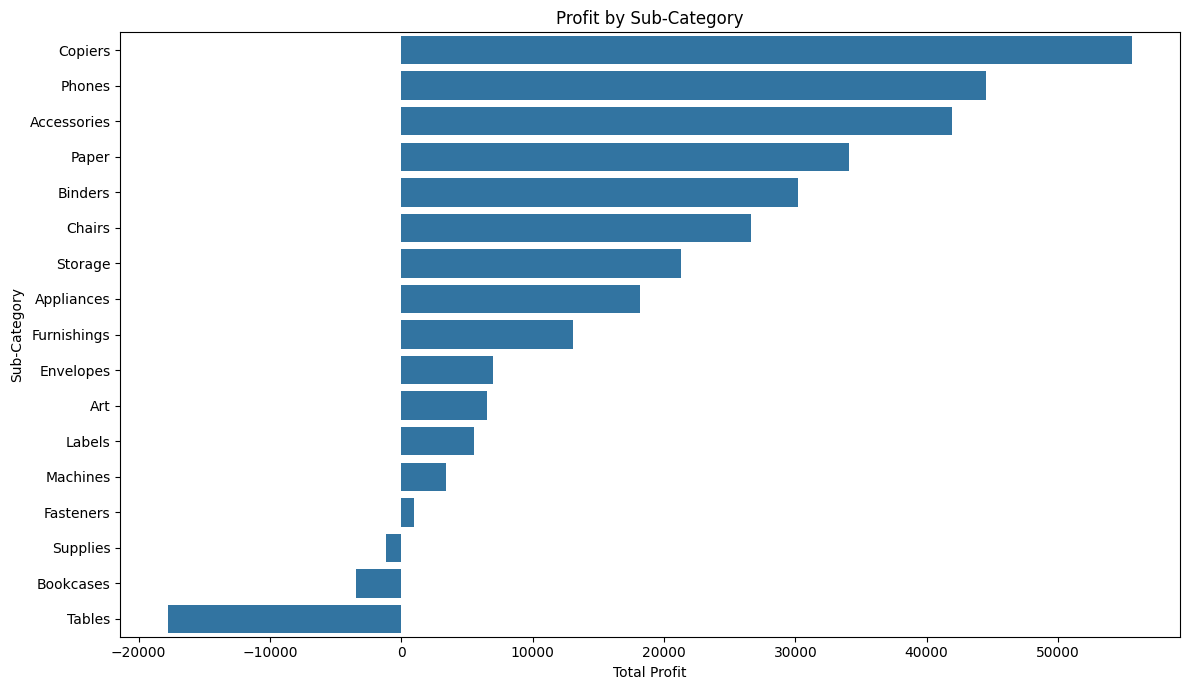

In [114]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=subcategory_profit.values,
    y=subcategory_profit.index
)

plt.title('Profit by Sub-Category')
plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')

plt.tight_layout()
plt.show()

In [115]:
print("Most Profitable Category:", category_profit.idxmax())

print("Most Profitable Sub-Category:", subcategory_profit.idxmax())

print("Lowest Profit Sub-Category:", subcategory_profit.idxmin())

print("Highest Profit:", round(subcategory_profit.max(), 2))

print("Lowest Profit:", round(subcategory_profit.min(), 2))

Most Profitable Category: Technology
Most Profitable Sub-Category: Copiers
Lowest Profit Sub-Category: Tables
Highest Profit: 55617.82
Lowest Profit: -17725.48


In [116]:
discount_profit = (
    df.groupby('Discount')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Discount=('Discount', 'mean')
    )
    .reset_index()
)

display(discount_profit)

,Discount,Total_Sales,Total_Profit,Average_Discount
0,0.00,1.087908e+06,320987.6032,0.00
1,0.10,5.436935e+04,9029.1770,0.10
2,0.15,2.755852e+04,1418.9915,0.15
3,0.20,7.645944e+05,90337.3060,0.20
4,0.30,1.032267e+05,-10369.2774,0.30
5,0.32,1.449346e+04,-2391.1377,0.32
6,0.40,1.164178e+05,-23057.0504,0.40
7,0.45,5.484974e+03,-2493.1111,0.45
8,0.50,5.891854e+04,-20506.4281,0.50
9,0.60,6.644700e+03,-5944.6552,0.60


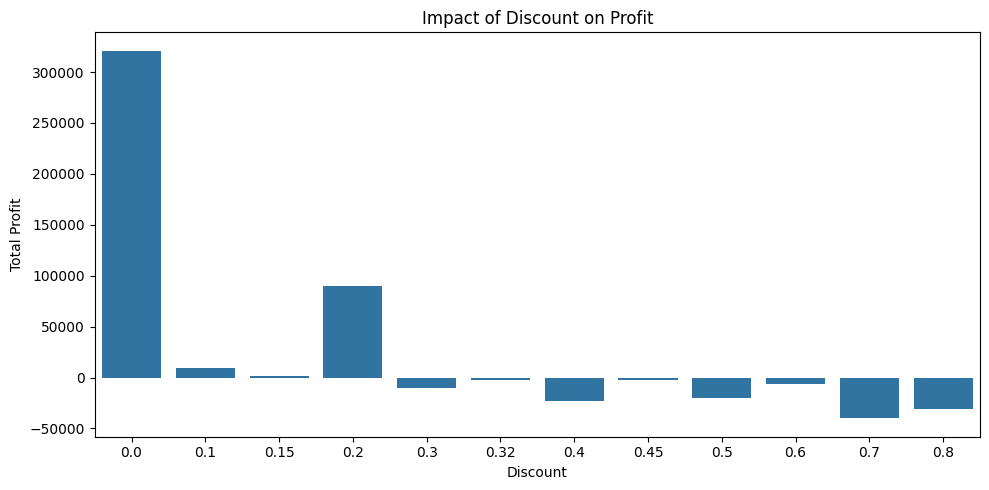

In [117]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_profit,
    x='Discount',
    y='Total_Profit'
)

plt.title('Impact of Discount on Profit')
plt.xlabel('Discount')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.show()

In [118]:
shipping_sales = (
    df.groupby('Ship Mode')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Shipping Mode:")
print(shipping_sales)

Sales by Shipping Mode:
Ship Mode
Standard Class    1.358216e+06
Second Class      4.591936e+05
First Class       3.514284e+05
Same Day          1.283631e+05
Name: Sales, dtype: float64


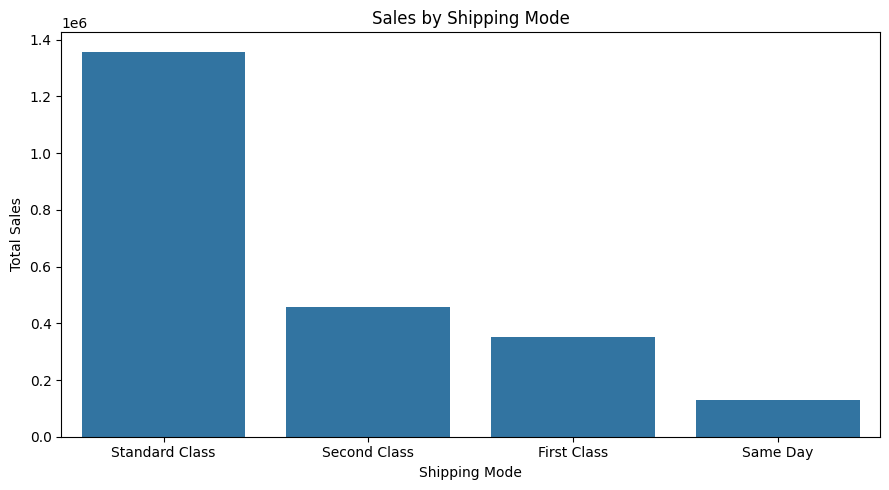

In [119]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=shipping_sales.index,
    y=shipping_sales.values
)

plt.title('Sales by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [120]:
shipping_profit = (
    df.groupby('Ship Mode')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Shipping Mode:")
print(shipping_profit)

Profit by Shipping Mode:
Ship Mode
Standard Class    164088.7875
Second Class       57446.6354
First Class        48969.8399
Same Day           15891.7589
Name: Profit, dtype: float64


In [121]:
shipping_orders = (
    df.groupby('Ship Mode')['Order ID']
    .nunique()
    .sort_values(ascending=False)
)

print("Orders by Shipping Mode:")
print(shipping_orders)

Orders by Shipping Mode:
Ship Mode
Standard Class    2994
Second Class       964
First Class        787
Same Day           264
Name: Order ID, dtype: int64


In [122]:
df['Shipping_Days'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

shipping_time = (
    df.groupby('Ship Mode')['Shipping_Days']
    .mean()
    .sort_values()
)

print("Average Shipping Days:")
print(shipping_time)

Average Shipping Days:
Ship Mode
Same Day          0.044199
First Class       2.182705
Second Class      3.238046
Standard Class    5.006535
Name: Shipping_Days, dtype: float64


In [123]:
shipping_summary = df.groupby('Ship Mode').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Average_Shipping_Days=('Shipping_Days', 'mean')
)

display(shipping_summary)

,Total_Sales,Total_Profit,Total_Orders,Average_Shipping_Days
Ship Mode,,,,
First Class,3.514284e+05,48969.8399,787,2.182705
Same Day,1.283631e+05,15891.7589,264,0.044199
Second Class,4.591936e+05,57446.6354,964,3.238046
Standard Class,1.358216e+06,164088.7875,2994,5.006535


In [124]:
numeric_columns = [
    'Sales',
    'Quantity',
    'Discount',
    'Profit'
]

correlation_data = df[numeric_columns]

correlation_data.head()

,Sales,Quantity,Discount,Profit
0,261.9600,2,0.00,41.9136
1,731.9400,3,0.00,219.5820
2,14.6200,2,0.00,6.8714
3,957.5775,5,0.45,-383.0310
4,22.3680,2,0.20,2.5164


In [125]:
correlation = correlation_data.corr()

print("Correlation Matrix:")
display(correlation)

Correlation Matrix:


,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


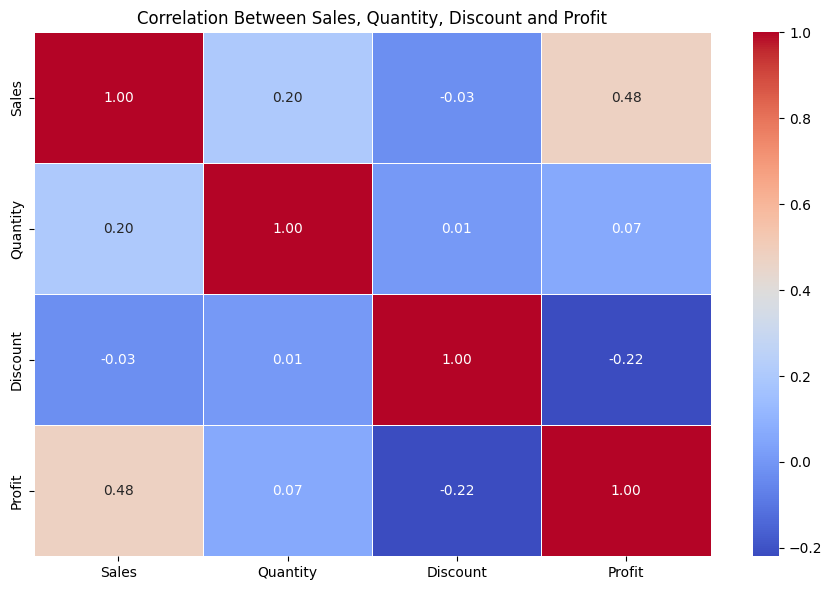

In [126]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Sales, Quantity, Discount and Profit')

plt.tight_layout()
plt.show()

In [127]:
discount_profit_corr = df['Discount'].corr(df['Profit'])

print(
    "Correlation between Discount and Profit:",
    round(discount_profit_corr, 3)
)

Correlation between Discount and Profit: -0.219


In [128]:
sales_profit_corr = df['Sales'].corr(df['Profit'])

print(
    "Correlation between Sales and Profit:",
    round(sales_profit_corr, 3)
)

Correlation between Sales and Profit: 0.479


In [129]:
print("========== BUSINESS INSIGHTS ==========")

print("\n1. SALES PERFORMANCE")
print("Total Sales:", round(df['Sales'].sum(), 2))
print("Total Profit:", round(df['Profit'].sum(), 2))

print("\n2. PRODUCT PERFORMANCE")
print("Top Selling Product:", product_sales.idxmax())
print("Top Selling Category:", category_sales.idxmax())

print("\n3. CUSTOMER PERFORMANCE")
print("Top Customer:", customer_sales.idxmax())
print("Total Customers:", df['Customer ID'].nunique())

print("\n4. REGIONAL PERFORMANCE")
print("Top Region:", region_sales.idxmax())
print("Top State:", state_sales.idxmax())
print("Top City:", city_sales.idxmax())

print("\n5. PROFIT PERFORMANCE")
print("Most Profitable Category:", category_profit.idxmax())
print("Least Profitable Sub-Category:", subcategory_profit.idxmin())

print("\n6. SHIPPING PERFORMANCE")
print("Most Used Shipping Mode:", shipping_orders.idxmax())
print("Fastest Shipping Mode:", shipping_time.idxmin())

========== BUSINESS INSIGHTS ==========

1. SALES PERFORMANCE
Total Sales: 2297200.86
Total Profit: 286397.02

2. PRODUCT PERFORMANCE
Top Selling Product: Canon imageCLASS 2200 Advanced Copier
Top Selling Category: Technology

3. CUSTOMER PERFORMANCE
Top Customer: Sean Miller
Total Customers: 793

4. REGIONAL PERFORMANCE
Top Region: West
Top State: California
Top City: New York City

5. PROFIT PERFORMANCE
Most Profitable Category: Technology
Least Profitable Sub-Category: Tables

6. SHIPPING PERFORMANCE
Most Used Shipping Mode: Standard Class
Fastest Shipping Mode: Same Day


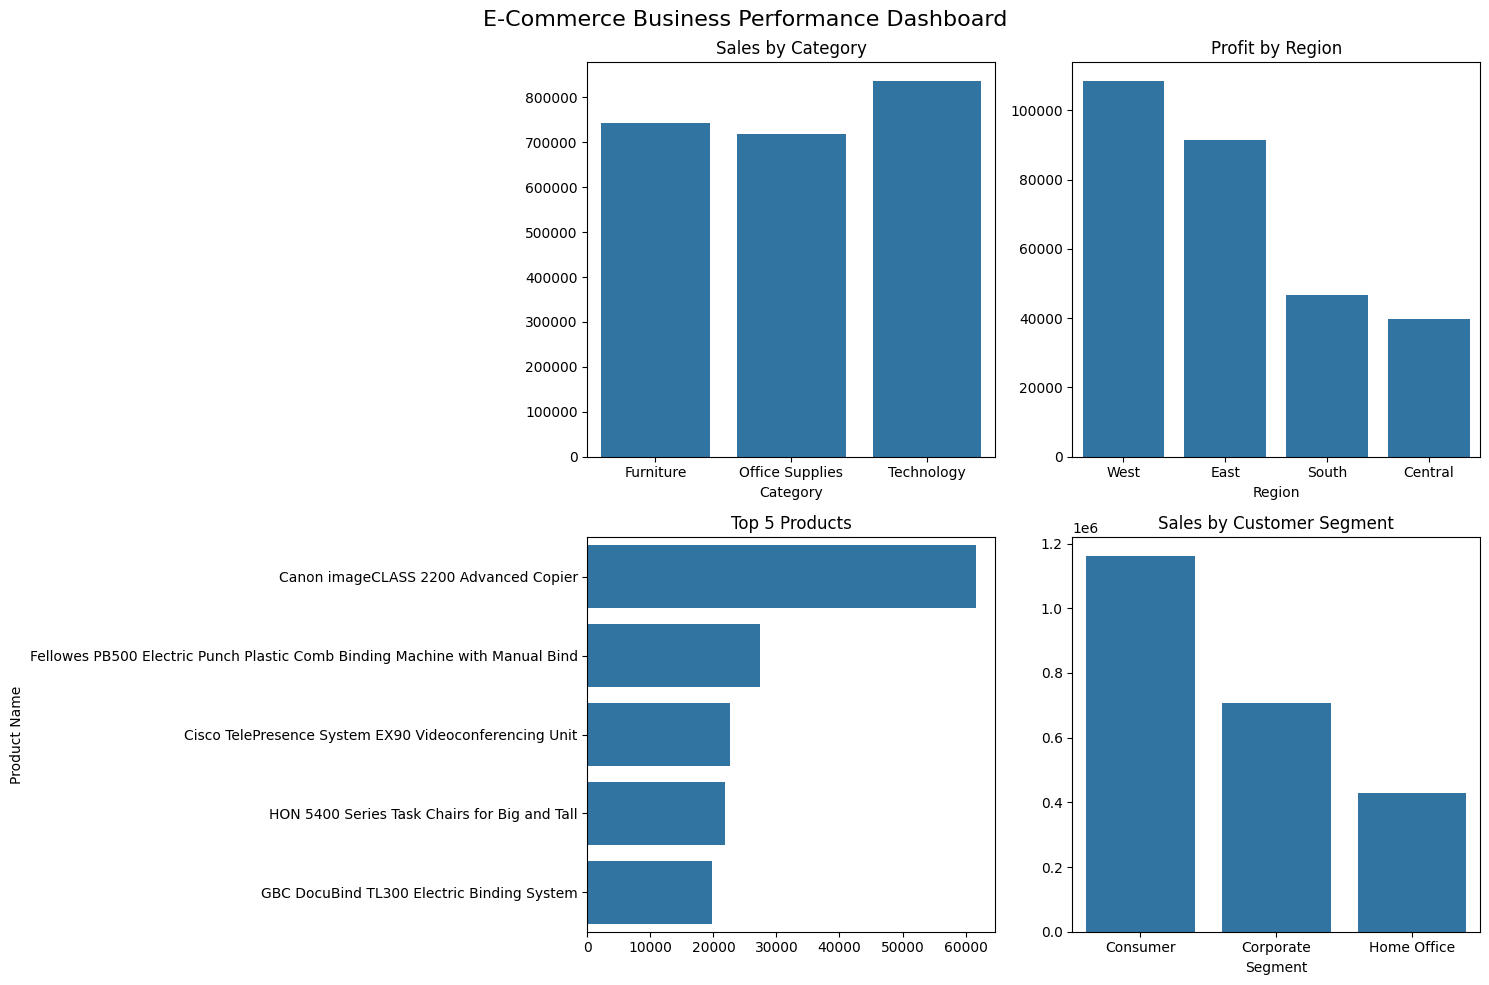

In [130]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Sales by category
sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Sales by Category')

# Profit by region
sns.barplot(
    x=region_profit.index,
    y=region_profit.values,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Profit by Region')

# Top 5 products
sns.barplot(
    x=top_10_products.head(5).values,
    y=top_10_products.head(5).index,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Top 5 Products')

# Sales by segment
sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Sales by Customer Segment')

plt.suptitle('E-Commerce Business Performance Dashboard', fontsize=16)
plt.tight_layout()
plt.show()

In [131]:
# Export cleaned dataset
df.to_csv(
    '/content/Cleaned_Superstore_Data.csv',
    index=False
)

# Export analysis results
monthly_sales.to_csv(
    '/content/Monthly_Sales_Analysis.csv',
    index=False
)

top_10_products.to_csv(
    '/content/Top_10_Products.csv'
)

top_10_customers.to_csv(
    '/content/Top_10_Customers.csv'
)

regional_summary.to_csv(
    '/content/Regional_Sales_Analysis.csv'
)

print("All analysis files exported successfully!")

All analysis files exported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')